In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
DATA = r"C:\Users\Shweta\Downloads\German_Traffic_Sign_Detection_Recognition"

In [3]:
print(os.listdir(DATA))

['Meta', 'Meta.csv', 'Test', 'Test.csv', 'Train', 'Train.csv']


In [4]:
train = pd.read_csv(os.path.join(DATA, "Train.csv"))

print(train.shape)
print(train.columns.tolist())
train.head()

(39209, 8)
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


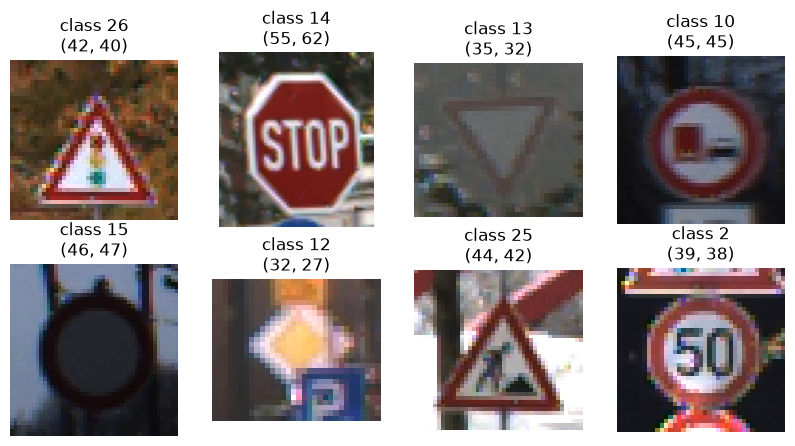

In [5]:
sample = train.sample(8, random_state=42)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
    img = Image.open(os.path.join(DATA, row["Path"]))
    ax.imshow(img)
    ax.set_title(f"class {row['ClassId']}\n{img.size}")
    ax.axis("off")
plt.show()

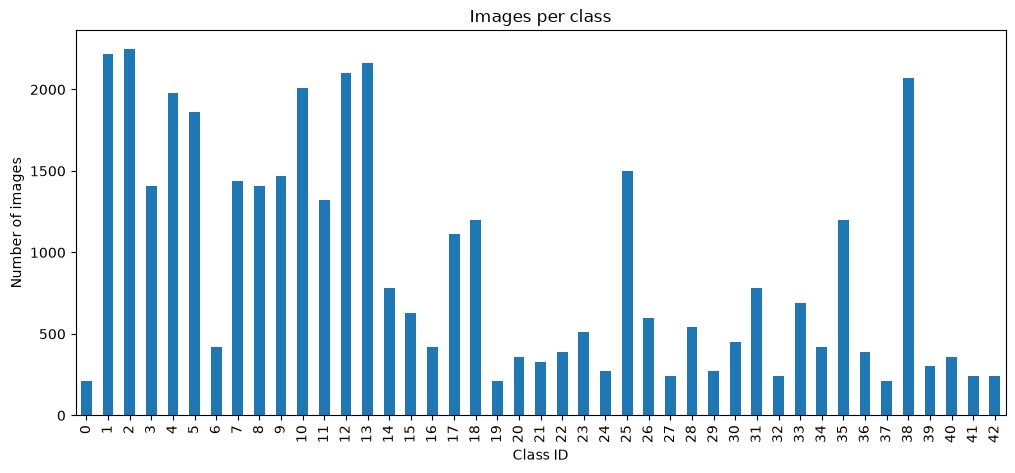

In [20]:
class_counts = train["ClassId"].value_counts().sort_index()
plt.figure(figsize=(12, 5))
class_counts.plot(kind="bar")
plt.title("Images per class")
plt.xlabel("Class ID")
plt.ylabel("Number of images")
plt.show()

In [24]:
print(train[["Width", "Height"]].describe())

train["Ratio"] = train["Width"] / train["Height"]
print(train["Ratio"].describe())

              Width        Height
count  39209.000000  39209.000000
mean      50.835880     50.328930
std       24.306933     23.115423
min       25.000000     25.000000
25%       35.000000     35.000000
50%       43.000000     43.000000
75%       58.000000     58.000000
max      243.000000    225.000000
count    39209.000000
mean         1.007442
std          0.070825
min          0.368132
25%          0.971429
50%          1.000000
75%          1.040816
max          1.417808
Name: Ratio, dtype: float64


In [26]:
import torch
import torchvision
print(torch.__version__)
print(torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

2.14.1+cpu
0.29.1+cpu
GPU available: False
